# Analyze Saved Benchmark Runs

This notebook loads one saved run from `results/` and creates a compact, student-friendly analysis of the holdout results.

It supports both of these layouts:

1. A flat run directory with one shared summary file and shared `history/` and `models/` folders.
2. A nested run directory like `cpcn-h200`, where each benchmark has its own subdirectory with its own summary, history, and model artifacts.

It focuses on two kinds of figures:

1. For each test function, one `2 x 2` comparison figure with:
   - `MAPE` results
   - runtime results
   - `R^2` results
   - `MAPE` vs `R^2`
2. Learning-behaviour figures based on the saved history files, using only:
   - train mean
   - validation mean
   - a confidence band (`mean +/- 1 std`)

The goal is to make the comparisons easy to read without too much clutter.


## Setup

Set the run name in the next cell. The notebook then reads the saved summary CSV files and history JSON files for that run, whether they are stored in a flat folder or split into benchmark subfolders.


In [20]:
from pathlib import Path
import json
import os
import re
import sys

mpl_config = Path("/tmp/matplotlib")
mpl_config.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_config))

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())
sys.path.insert(0, str(repo_root / "src"))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


In [21]:
RUN_NAME = "cpcn-h200"
SUMMARY_FILES = ("cpcn_benchmark.csv", "architecture_comparison.csv")
RUN_CONFIG_FILE = "run_config.json"
SHOW_FUNCTIONS = None  # Example: ["ackley", "rastrigin"]
SHOW_MODELS = None     # Example: ["CPCN", "CMLP", "GHR"]
FIG_DPI = 120


In [22]:
def _iter_run_sections(run_dir: Path) -> list[Path]:
    if any((run_dir / filename).exists() for filename in SUMMARY_FILES):
        return [run_dir]

    section_dirs = [
        path
        for path in sorted(run_dir.iterdir())
        if path.is_dir()
        and (
            any((path / filename).exists() for filename in SUMMARY_FILES)
            or (path / RUN_CONFIG_FILE).exists()
            or (path / "history").exists()
            or (path / "models").exists()
        )
    ]
    return section_dirs or [run_dir]


def _load_summary_frame(section_dir: Path) -> pd.DataFrame | None:
    for filename in SUMMARY_FILES:
        summary_path = section_dir / filename
        if summary_path.exists():
            summary_df = pd.read_csv(summary_path)
            summary_df["source_run"] = section_dir.name
            return summary_df
    return None


def _load_run_summary(run_dir: Path) -> tuple[pd.DataFrame, list[Path]]:
    section_dirs = _iter_run_sections(run_dir)
    frames: list[pd.DataFrame] = []
    skipped_sections: list[Path] = []

    for section_dir in section_dirs:
        section_summary = _load_summary_frame(section_dir)
        if section_summary is None:
            skipped_sections.append(section_dir)
            continue

        frames.append(section_summary)

    if not frames:
        raise FileNotFoundError(f"No readable summary files were found under {run_dir}.")

    summary_df = pd.concat(frames, ignore_index=True)

    if "algorithm" in summary_df.columns:
        summary_df["algorithm"] = summary_df["algorithm"].astype(str).str.upper()

    return summary_df, skipped_sections


def _extract_history_series(payload: dict, candidate_keys: list[str]) -> list[float]:
    for key in candidate_keys:
        if key in payload:
            return payload[key]
    raise KeyError(f"None of the expected history keys were found: {candidate_keys}")


In [23]:
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())
results_root = repo_root / "results"
available_runs = sorted(path.name for path in results_root.iterdir() if path.is_dir())
run_dir = results_root / RUN_NAME

if not run_dir.exists():
    raise FileNotFoundError(f"Run directory not found: {run_dir}")

summary_df, skipped_sections = _load_run_summary(run_dir)

print(f"Repo root: {repo_root}")
print(f"Available runs: {available_runs}")
print(f"Selected run: {run_dir}")
print(f"Loaded summary rows: {len(summary_df)}")
print(f"Summary sections loaded: {sorted(summary_df['source_run'].unique())}")
if skipped_sections:
    print(f"Skipped incomplete sections: {[section.name for section in skipped_sections]}")


Repo root: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN
Available runs: ['archcmp_resume', 'archcmp_resume_old', 'cpcn-h200', 'pcn-h200', 'pcn-h200-search', 'slurm_138915']
Selected run: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/results/cpcn-h200
Loaded summary rows: 3
Summary sections loaded: ['ackley', 'rastrigin', 'schwefel']
Skipped incomplete sections: ['griewank']


In [24]:
if SHOW_FUNCTIONS is not None:
    summary_df = summary_df[summary_df["test_function"].isin(SHOW_FUNCTIONS)].copy()
if SHOW_MODELS is not None:
    summary_df = summary_df[summary_df["algorithm"].isin(SHOW_MODELS)].copy()

if summary_df.empty:
    raise ValueError("The selected filters removed all rows.")

preferred_function_order = ["ackley", "griewank", "rastrigin", "schwefel"]
function_order = [name for name in preferred_function_order if name in set(summary_df["test_function"])]
function_order += [name for name in sorted(summary_df["test_function"].unique()) if name not in function_order]

preferred_model_order = ["CPCN", "CMLP", "GHR", "Arena", "Nitta"]
model_order = [name for name in preferred_model_order if name in set(summary_df["algorithm"])]
model_order += [name for name in sorted(summary_df["algorithm"].unique()) if name not in model_order]

summary_df["test_function"] = pd.Categorical(summary_df["test_function"], categories=function_order, ordered=True)
summary_df["algorithm"] = pd.Categorical(summary_df["algorithm"], categories=model_order, ordered=True)
summary_df = summary_df.sort_values(["test_function", "algorithm", "repetition"]).reset_index(drop=True)

summary_df


,repetition,algorithm,test_function,activation,optimizer,layer_sizes,batch_size,eta_infer,eta_learn,T_infer_train,...,test_r2,test_normalized_mse,test_normalized_mae,test_quaternion_mae,test_free_energy,status,epochs,runtime_seconds,evals,source_run
0,1,CPCN,ackley,tanh,SGD,1-5-5-5-1,512,0.01,0.0001,16,...,-0.000142,1.026669,0.664030,0.66403,0.243795,completed,250,1159.798325,51,ackley
1,1,CPCN,rastrigin,tanh,SGD,1-5-5-5-1,512,0.01,0.0001,16,...,-0.000073,0.942592,0.777311,0.77739,0.147662,completed,250,1083.025289,51,rastrigin
2,1,CPCN,schwefel,tanh,SGD,1-5-5-5-1,512,0.01,0.0001,16,...,0.000310,0.979173,0.789674,0.78977,0.151666,completed,250,1106.128066,51,schwefel


## Summary Tables

`MAPE` and `R^2` come from the holdout test set. Runtime is the training runtime saved for each run.

The first table is a tidy summary per function and model. The second table is a pivoted version for quicker side-by-side comparison.


In [25]:
def _format_mean_std(mean_value: float, std_value: float, digits: int = 4) -> str:
    if pd.isna(std_value):
        std_value = 0.0
    return f"{mean_value:.{digits}f} +/- {std_value:.{digits}f}"

summary_stats = (
    summary_df.groupby(["test_function", "algorithm"], observed=True)
    .agg(
        runs=("repetition", "count"),
        mape_mean=("test_mape", "mean"),
        mape_std=("test_mape", "std"),
        r2_mean=("test_r2", "mean"),
        r2_std=("test_r2", "std"),
        runtime_mean=("runtime_seconds", "mean"),
        runtime_std=("runtime_seconds", "std"),
    )
    .reset_index()
)

summary_stats["MAPE"] = summary_stats.apply(lambda row: _format_mean_std(row.mape_mean, row.mape_std), axis=1)
summary_stats["R^2"] = summary_stats.apply(lambda row: _format_mean_std(row.r2_mean, row.r2_std), axis=1)
summary_stats["Runtime (s)"] = summary_stats.apply(lambda row: _format_mean_std(row.runtime_mean, row.runtime_std, digits=2), axis=1)

tidy_table = summary_stats[["test_function", "algorithm", "runs", "MAPE", "R^2", "Runtime (s)"]]
display(tidy_table)

pivot_table = (
    summary_stats.set_index(["test_function", "algorithm"])[["MAPE", "R^2", "Runtime (s)"]]
    .unstack("algorithm")
)
display(pivot_table)


,test_function,algorithm,runs,MAPE,R^2,Runtime (s)
0,ackley,CPCN,1,0.0390 +/- 0.0000,-0.0001 +/- 0.0000,1159.80 +/- 0.00
1,rastrigin,CPCN,1,0.2573 +/- 0.0000,-0.0001 +/- 0.0000,1083.03 +/- 0.00
2,schwefel,CPCN,1,0.2058 +/- 0.0000,0.0003 +/- 0.0000,1106.13 +/- 0.00


,MAPE,R^2,Runtime (s)
algorithm,CPCN,CPCN,CPCN
test_function,,,
ackley,0.0390 +/- 0.0000,-0.0001 +/- 0.0000,1159.80 +/- 0.00
rastrigin,0.2573 +/- 0.0000,-0.0001 +/- 0.0000,1083.03 +/- 0.00
schwefel,0.2058 +/- 0.0000,0.0003 +/- 0.0000,1106.13 +/- 0.00


## Plot Helpers

The next helpers keep the figures visually consistent and easy to read. Every model gets the same color in every plot.


In [26]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = FIG_DPI

palette = plt.get_cmap("tab10")
model_colors = {model: palette(idx) for idx, model in enumerate(model_order)}


def _present_models(df: pd.DataFrame) -> list[str]:
    return [model for model in model_order if model in set(df["algorithm"])]


def _boxplot_with_points(ax, df: pd.DataFrame, metric_col: str, ylabel: str, title: str):
    present_models = _present_models(df)
    values = [df.loc[df["algorithm"] == model, metric_col].to_numpy() for model in present_models]
    positions = np.arange(1, len(present_models) + 1)

    box = ax.boxplot(values, positions=positions, widths=0.6, patch_artist=True, tick_labels=present_models)
    for patch, model in zip(box["boxes"], present_models):
        patch.set_facecolor(model_colors[model])
        patch.set_alpha(0.45)
    for median in box["medians"]:
        median.set_color("black")
        median.set_linewidth(1.6)

    for xpos, model, series in zip(positions, present_models, values):
        if len(series) == 0:
            continue
        offsets = np.linspace(-0.07, 0.07, num=len(series)) if len(series) > 1 else np.array([0.0])
        ax.scatter(
            np.full(len(series), xpos) + offsets,
            series,
            color=model_colors[model],
            edgecolor="black",
            linewidth=0.5,
            s=34,
            zorder=3,
        )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(ylabel)


def plot_function_comparison(function_name: str, df: pd.DataFrame):
    function_df = df[df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), squeeze=False)
    axes = axes.ravel()

    _boxplot_with_points(
        axes[0],
        function_df,
        metric_col="test_mape",
        ylabel="MAPE",
        title=f"{function_name.capitalize()} MAPE Results (lower is better)",
    )
    _boxplot_with_points(
        axes[1],
        function_df,
        metric_col="runtime_seconds",
        ylabel="Runtime (seconds)",
        title=f"{function_name.capitalize()} Runtime Results (lower is better)",
    )
    _boxplot_with_points(
        axes[2],
        function_df,
        metric_col="test_r2",
        ylabel="R^2",
        title=f"{function_name.capitalize()} R^2 Results (higher is better)",
    )

    for model in present_models:
        model_df = function_df[function_df["algorithm"] == model]
        axes[3].scatter(
            model_df["test_mape"],
            model_df["test_r2"],
            color=model_colors[model],
            s=60,
            alpha=0.9,
            edgecolor="black",
            linewidth=0.5,
            label=model,
        )
    axes[3].set_title(f"{function_name.capitalize()} MAPE vs R^2")
    axes[3].set_xlabel("MAPE")
    axes[3].set_ylabel("R^2")
    axes[3].legend(title="Model")

    fig.suptitle(f"Holdout Comparison for {function_name.capitalize()}", fontsize=15, y=1.02)
    fig.tight_layout()
    return fig


## Plot Type 1: Holdout Comparison per Function

Read each figure like this:

- the first three panels compare the holdout distributions across models
- the last panel shows the trade-off between `MAPE` and `R^2`
- better models are usually toward **low MAPE**, **low runtime**, and **high `R^2`**


### Ackley

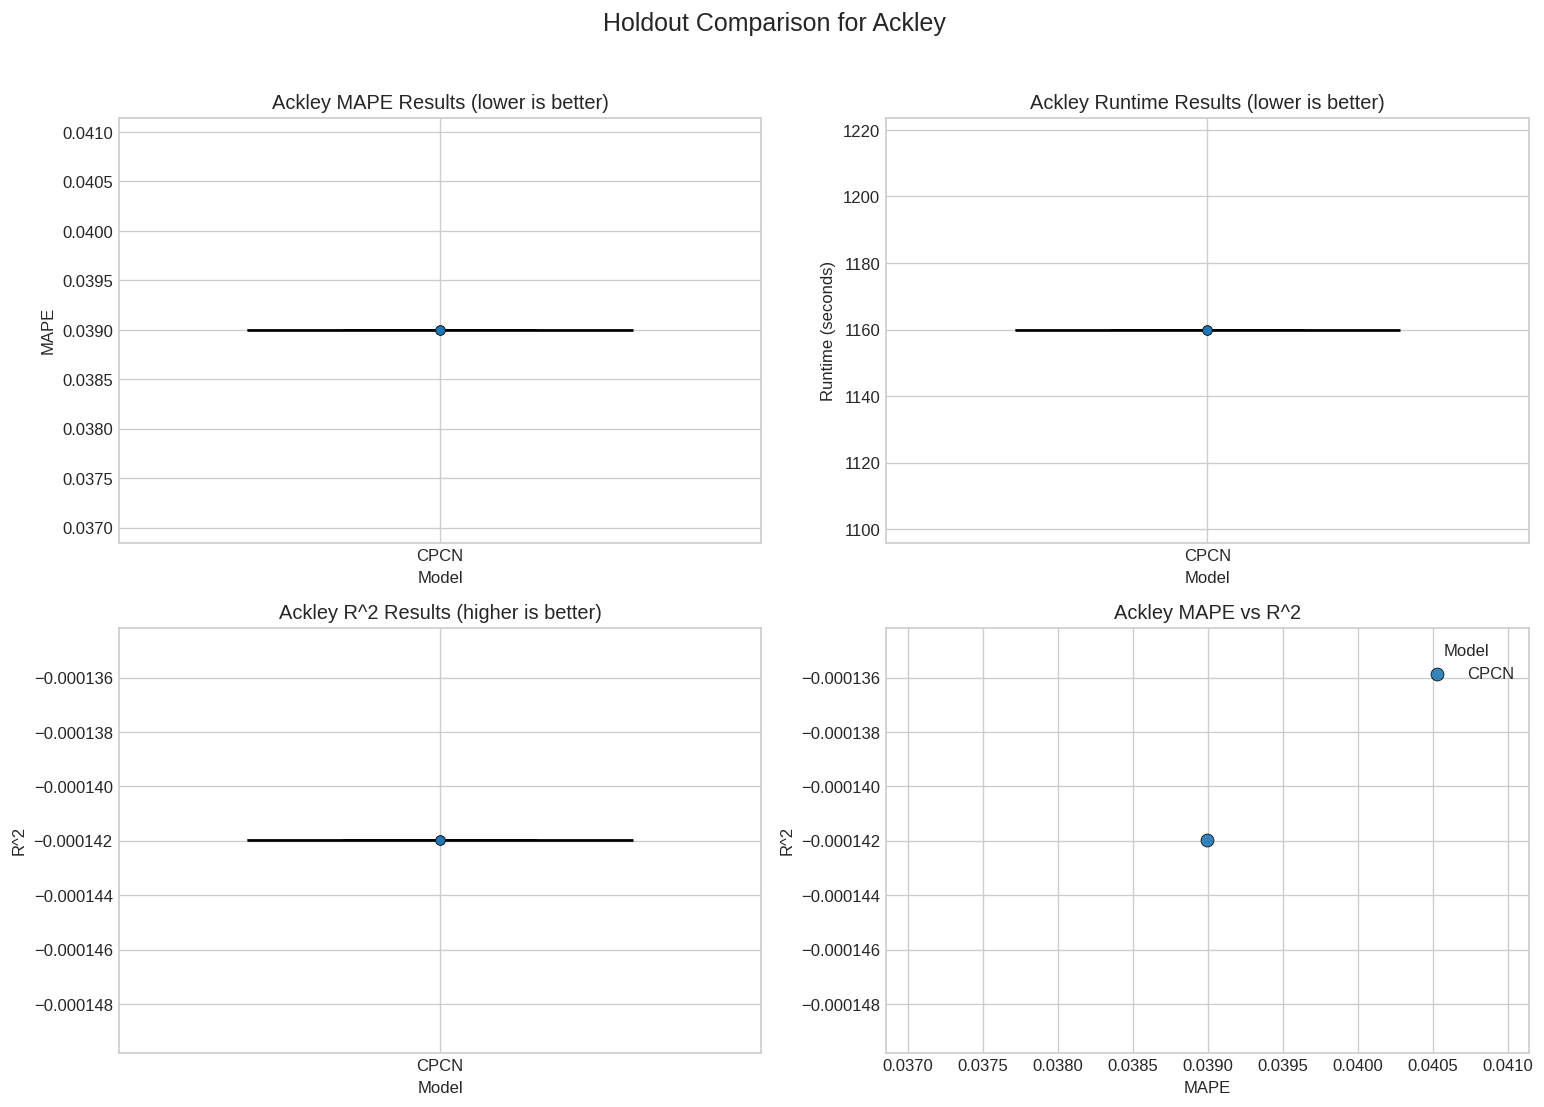

### Rastrigin

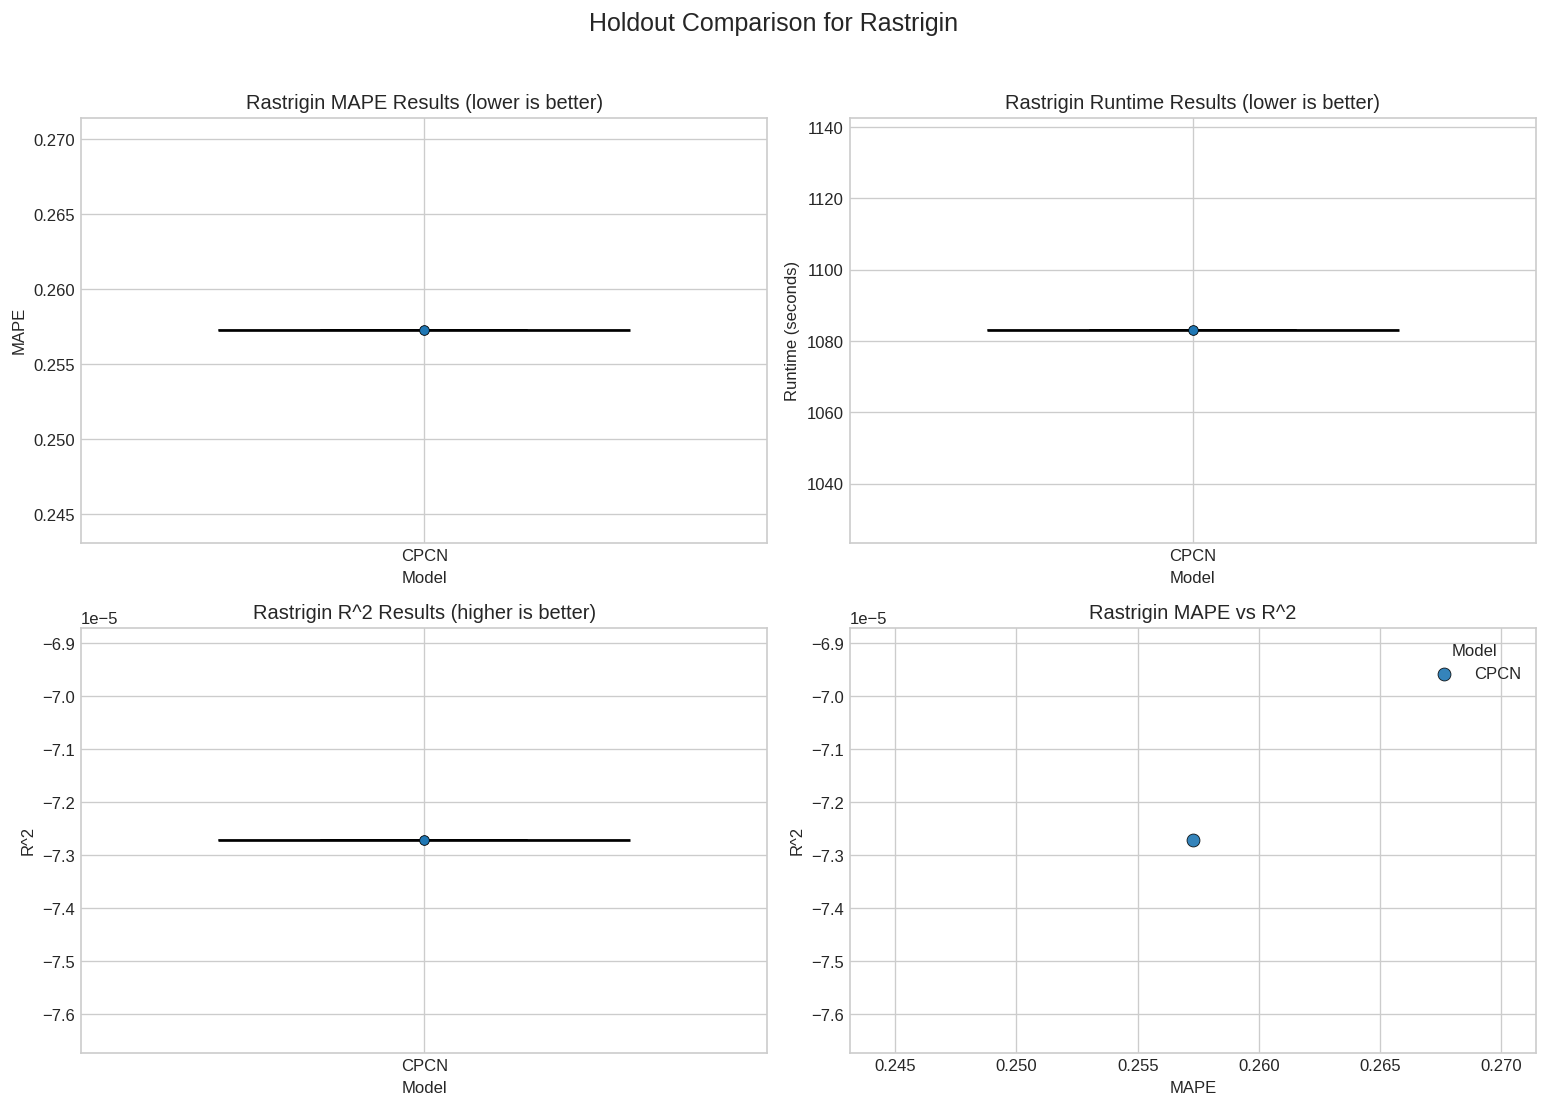

### Schwefel

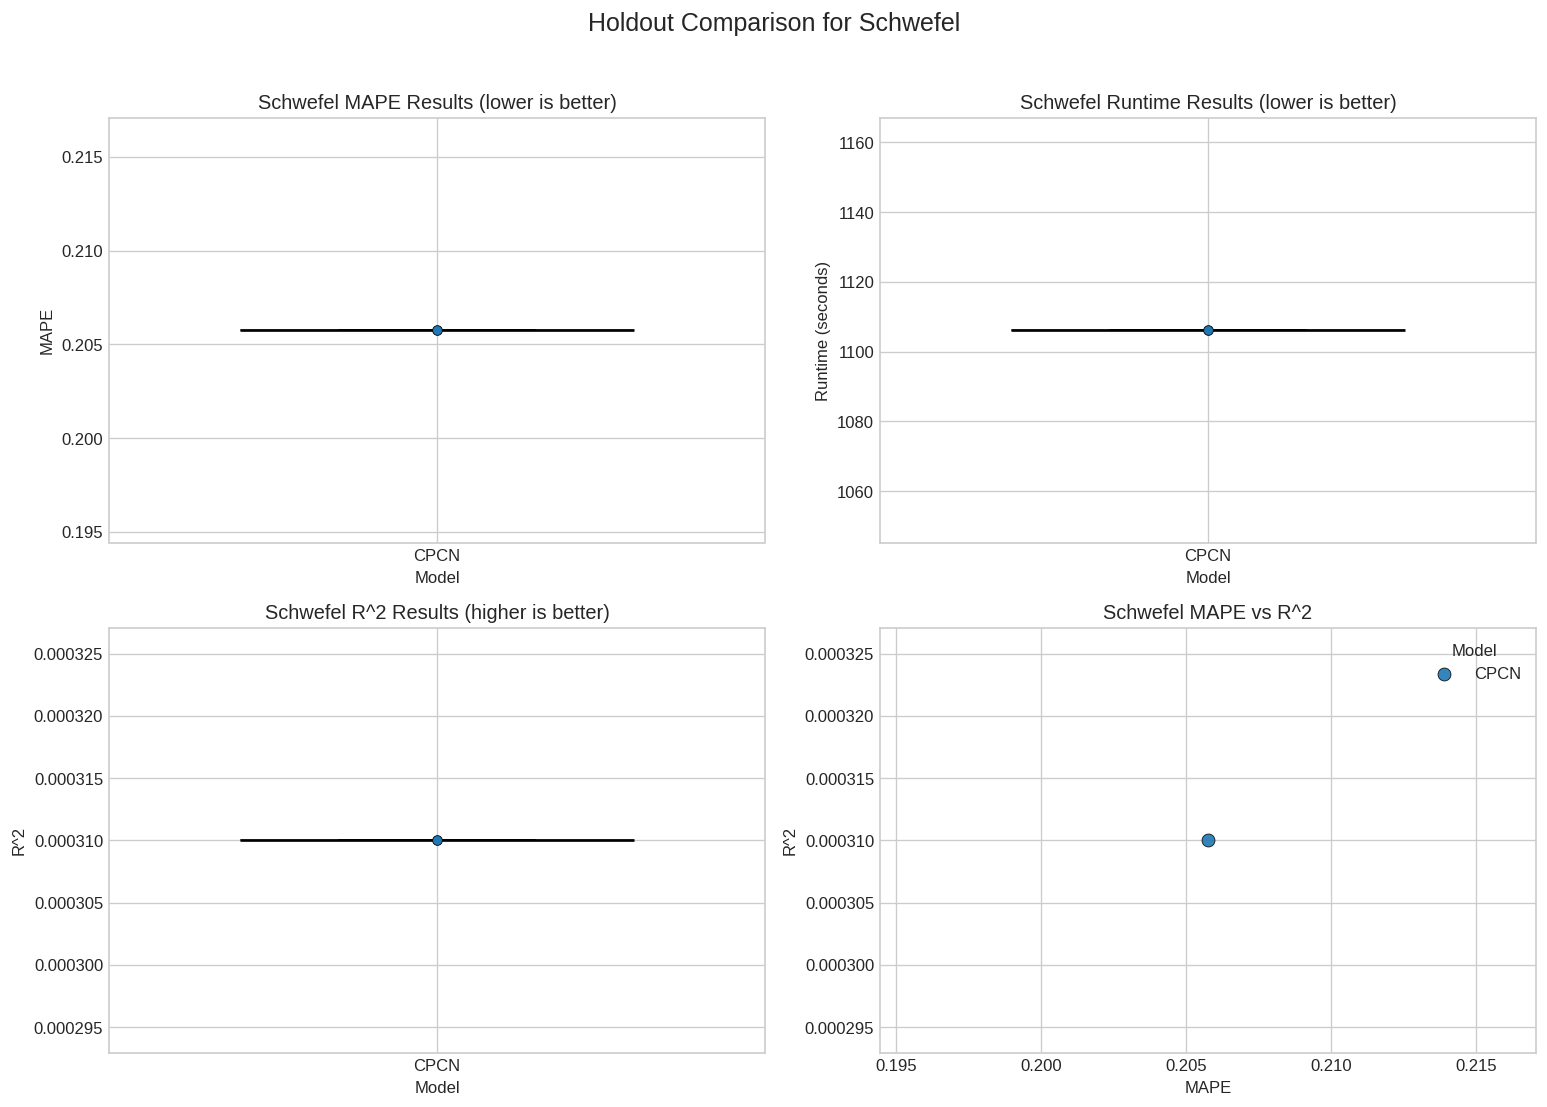

In [27]:
for function_name in function_order:
    display(Markdown(f"### {function_name.capitalize()}"))
    plot_function_comparison(function_name, summary_df)
    plt.show()


## Learning Behaviour Data

The saved history files contain per-epoch:

- training MAE
- validation MAE
- training MAPE
- training `R^2`

For clean learning plots, we will only use training and validation MAE and aggregate them across repetitions.


In [28]:
history_pattern = re.compile(r"(?P<function>.+)_(?P<algorithm>[^_]+)_rep(?P<rep>\d+)\.json")

history_rows = []
for section_dir in _iter_run_sections(run_dir):
    history_dir = section_dir / "history"
    if not history_dir.exists():
        continue

    for history_path in sorted(history_dir.glob("*.json")):
        match = history_pattern.fullmatch(history_path.name)
        if match is None:
            continue
        function_name = match.group("function")
        algorithm_name = match.group("algorithm").upper()
        repetition = int(match.group("rep"))
        payload = json.loads(history_path.read_text())
        train_values = _extract_history_series(payload, ["quaternion_mae", "train_quaternion_mae", "train_mae"])
        validation_values = _extract_history_series(payload, [
            "validation_quaternion_mae",
            "val_quaternion_mae",
            "validation_mae",
            "val_mae",
        ])
        curve_length = min(len(train_values), len(validation_values))

        for epoch_idx in range(curve_length):
            history_rows.append(
                {
                    "test_function": function_name,
                    "algorithm": algorithm_name,
                    "repetition": repetition,
                    "epoch": epoch_idx + 1,
                    "train_mae": train_values[epoch_idx],
                    "validation_mae": validation_values[epoch_idx],
                }
            )

history_df = pd.DataFrame(history_rows)

if not history_df.empty:
    history_df["test_function"] = pd.Categorical(history_df["test_function"], categories=function_order, ordered=True)
    history_df["algorithm"] = pd.Categorical(history_df["algorithm"], categories=model_order, ordered=True)
    history_df = history_df.sort_values(["test_function", "algorithm", "repetition", "epoch"]).reset_index(drop=True)

history_df.head()


,test_function,algorithm,repetition,epoch,train_mae,validation_mae
0,ackley,CPCN,1,1,0.658442,0.668881
1,ackley,CPCN,1,2,0.658428,0.668867
2,ackley,CPCN,1,3,0.658462,0.668901
3,ackley,CPCN,1,4,0.658471,0.668911
4,ackley,CPCN,1,5,0.658473,0.668913


In [29]:
def _curve_stats(subset: pd.DataFrame, value_col: str) -> pd.DataFrame:
    stats = (
        subset.groupby("epoch", observed=True)[value_col]
        .agg(["mean", "std"])
        .reset_index()
        .rename(columns={"mean": f"{value_col}_mean", "std": f"{value_col}_std"})
    )
    stats[f"{value_col}_std"] = stats[f"{value_col}_std"].fillna(0.0)
    return stats


def plot_learning_behaviour_for_function(function_name: str, history_df: pd.DataFrame):
    function_df = history_df[history_df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)
    fig, axes = plt.subplots(1, len(present_models), figsize=(6.2 * len(present_models), 4.6), squeeze=False)
    axes = axes.ravel()

    train_color = "tab:blue"
    val_color = "tab:orange"

    for ax, model_name in zip(axes, present_models):
        subset = function_df[function_df["algorithm"] == model_name]
        train_stats = _curve_stats(subset, "train_mae")
        val_stats = _curve_stats(subset, "validation_mae")

        ax.plot(train_stats["epoch"], train_stats["train_mae_mean"], color=train_color, linewidth=2.2, label="Train mean")
        ax.fill_between(
            train_stats["epoch"],
            train_stats["train_mae_mean"] - train_stats["train_mae_std"],
            train_stats["train_mae_mean"] + train_stats["train_mae_std"],
            color=train_color,
            alpha=0.18,
            label="Train +/- 1 std",
        )

        ax.plot(val_stats["epoch"], val_stats["validation_mae_mean"], color=val_color, linewidth=2.2, linestyle="--", label="Validation mean")
        ax.fill_between(
            val_stats["epoch"],
            val_stats["validation_mae_mean"] - val_stats["validation_mae_std"],
            val_stats["validation_mae_mean"] + val_stats["validation_mae_std"],
            color=val_color,
            alpha=0.18,
            label="Validation +/- 1 std",
        )

        ax.set_title(f"{function_name.capitalize()} - {model_name}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MAE")

    legend_handles = [
        Line2D([0], [0], color=train_color, linewidth=2.2, label="Train mean"),
        Line2D([0], [0], color=val_color, linewidth=2.2, linestyle="--", label="Validation mean"),
        Line2D([0], [0], color=train_color, linewidth=8, alpha=0.18, label="Train +/- 1 std"),
        Line2D([0], [0], color=val_color, linewidth=8, alpha=0.18, label="Validation +/- 1 std"),
    ]
    fig.legend(handles=legend_handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
    fig.suptitle(f"Learning Behaviour for {function_name.capitalize()}", fontsize=15, y=1.08)
    fig.tight_layout()
    return fig


## Plot Type 2: Learning Behaviour

These plots are intentionally less cluttered than before:

- no single-run lines
- solid blue line = train mean
- dashed orange line = validation mean
- shaded band = `mean +/- 1 std` across repetitions

This makes it much easier to see the general trend of each model.


### Ackley

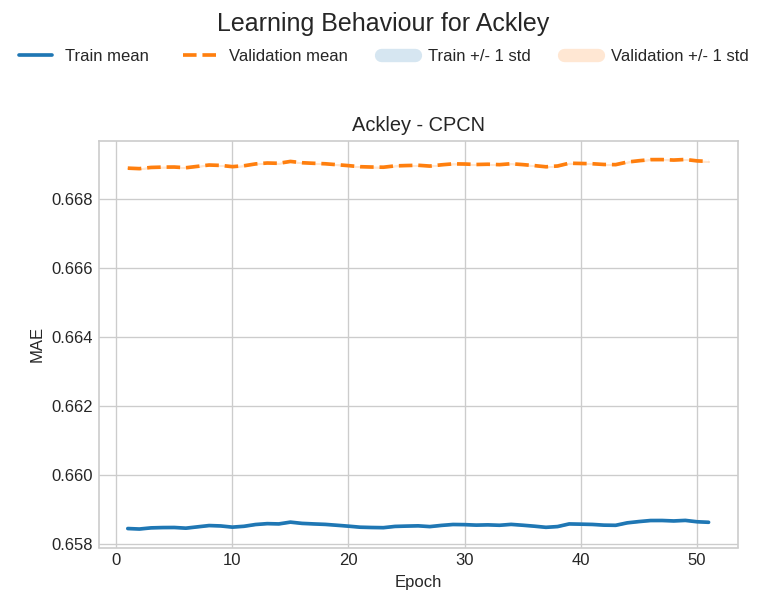

### Rastrigin

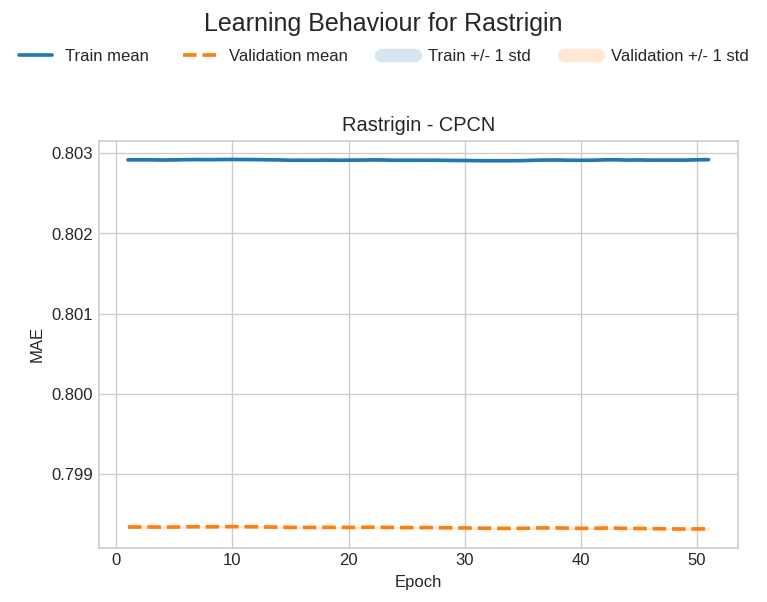

### Schwefel

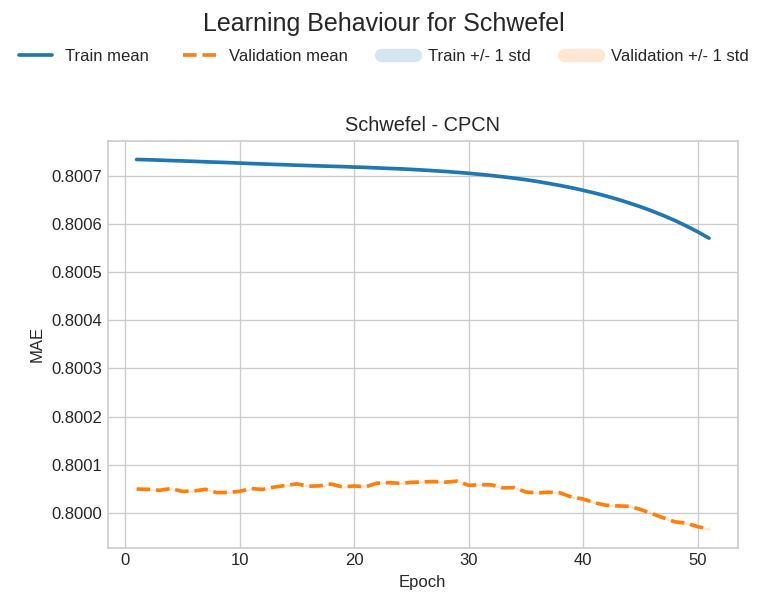

In [30]:
for function_name in function_order:
    display(Markdown(f"### {function_name.capitalize()}"))
    plot_learning_behaviour_for_function(function_name, history_df)
    plt.show()
